# Day 083 | Model Deployment (ONNX, TorchScript)

## 100 Days of ML for Geotechnical Engineering
**Phase:** Deep Learning | **Author:** Ripon Chandra Malo | **Date:** YYYY-MM-DD

---

## What We Will Learn Today

| Concept | What It Means | Geotechnical Example |
|---------|--------------|---------------------|
| state_dict save/load | Serialize model weights to disk | Save trained Vs predictor |
| TorchScript (trace) | Compile model to portable format | Run on field laptop without Python env |
| ONNX export | Cross-framework model exchange | Share model with MATLAB/C++ workflows |
| Predict function | End-to-end raw-input wrapper | Engineer inputs SPT data, gets Vs out |
| Model versioning | config.json with weights | Track which model version is in production |
| Inference speed | Compare Python vs TorchScript | Batch processing many boreholes fast |

---

## Our Geotechnical Problem

Yesterday we tuned a neural network to predict **Vs from SPT**.
Today we **package it** so a practicing geotechnical engineer can:

- Run it on any machine (even without PyTorch installed)
- Get a formatted result dictionary with units
- Call it from a simple REST API
- Trust that the model version matches the training run

```
  Training Machine          Production Machine
  ─────────────────         ────────────────────────────
  PyTorch + GPU             Any OS, minimal dependencies
  Tune + train NN  ──►  save  ──►  TorchScript / ONNX
  Export artifacts           Validate → predict()
                             Flask API endpoint
```

## Part 1: Train the Reference Vs Prediction Model

In [1]:
# ───────────────────────────────────────────────────────
# IMPORTS
# ───────────────────────────────────────────────────────

import torch
import torch.nn as nn
import numpy as np
import json
import time
import os
import tempfile
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error
import matplotlib.pyplot as plt

torch.manual_seed(42)
np.random.seed(42)

print("Libraries loaded.")
print(f"PyTorch version: {torch.__version__}")

Libraries loaded.
PyTorch version: 2.5.1


In [2]:
# ───────────────────────────────────────────────────────
# REPRODUCE Vs PREDICTION MODEL (same data as Day 082)
# ───────────────────────────────────────────────────────

np.random.seed(42)
n_samples       = 200
depth           = np.random.uniform(1, 30, n_samples)
n_value         = np.random.uniform(2, 60, n_samples)
fines_content   = np.random.uniform(0, 80, n_samples)
unit_weight     = np.random.uniform(16, 22, n_samples)
effective_stress = depth * (unit_weight - 9.81) * 0.5

Vs = 97.0 * (n_value ** 0.314) * (depth ** 0.12)
Vs *= (1 - 0.003 * fines_content)
Vs *= (1 + 0.001 * effective_stress)
Vs += np.random.normal(0, 15, n_samples)
Vs  = np.clip(Vs, 80, 800)

X = np.column_stack([depth, n_value, fines_content, unit_weight, effective_stress])
X_train, X_test, y_train, y_test = train_test_split(X, Vs, test_size=0.2, random_state=42)

scaler_X = StandardScaler()
X_train_sc = scaler_X.fit_transform(X_train)
X_test_sc  = scaler_X.transform(X_test)

scaler_y = StandardScaler()
y_train_sc = scaler_y.fit_transform(y_train.reshape(-1, 1)).flatten()
y_test_sc  = scaler_y.transform(y_test.reshape(-1, 1)).flatten()

X_tr = torch.tensor(X_train_sc, dtype=torch.float32)
y_tr = torch.tensor(y_train_sc, dtype=torch.float32).unsqueeze(1)
X_te = torch.tensor(X_test_sc,  dtype=torch.float32)
y_te = torch.tensor(y_test_sc,  dtype=torch.float32).unsqueeze(1)

# Define model
class VsNet(nn.Module):
    """Vs prediction from SPT parameters."""
    def __init__(self, in_features=5, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_features, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden),       nn.ReLU(),
            nn.Linear(hidden, 1)
        )
    def forward(self, x):
        return self.net(x)

model = VsNet(in_features=5, hidden=64)

# Quick training
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.MSELoss()

for epoch in range(300):
    model.train()
    perm = torch.randperm(X_tr.shape[0])
    for i in range(0, X_tr.shape[0], 32):
        idx = perm[i:i + 32]
        loss = criterion(model(X_tr[idx]), y_tr[idx])
        optimizer.zero_grad(); loss.backward(); optimizer.step()

model.eval()
with torch.no_grad():
    pred_sc = model(X_te).numpy().flatten()
pred = scaler_y.inverse_transform(pred_sc.reshape(-1, 1)).flatten()
r2   = r2_score(y_test, pred)
rmse = np.sqrt(mean_squared_error(y_test, pred))
print(f"Reference model — R²: {r2:.4f}  RMSE: {rmse:.2f} m/s")

Reference model — R²: 0.9662  RMSE: 17.09 m/s


---

## Part 2: Save and Load state_dict

In [3]:
# ───────────────────────────────────────────────────────
# SAVE / LOAD state_dict
# ───────────────────────────────────────────────────────

SAVE_DIR = tempfile.mkdtemp()  # use a temp directory for the demo
WEIGHTS_PATH = os.path.join(SAVE_DIR, 'vs_model_v1.pt')

# --- Save ---
torch.save(model.state_dict(), WEIGHTS_PATH)
size_kb = os.path.getsize(WEIGHTS_PATH) / 1024
print(f"Model saved: {WEIGHTS_PATH}")
print(f"File size:   {size_kb:.1f} KB")

# --- Load into a fresh model ---
loaded_model = VsNet(in_features=5, hidden=64)
loaded_model.load_state_dict(torch.load(WEIGHTS_PATH))
loaded_model.eval()

# Verify identical predictions
with torch.no_grad():
    pred_loaded_sc = loaded_model(X_te).numpy().flatten()
pred_loaded = scaler_y.inverse_transform(pred_loaded_sc.reshape(-1, 1)).flatten()

max_diff = np.abs(pred - pred_loaded).max()
print(f"\nMax prediction difference (original vs loaded): {max_diff:.2e} m/s")
print("✓ state_dict round-trip verified." if max_diff < 1e-4 else "Warning: mismatch detected")

# Inspect state_dict keys
print("\nstate_dict keys:")
for k, v in loaded_model.state_dict().items():
    print(f"  {k:30s}  shape={tuple(v.shape)}")

Model saved: /var/folders/7x/_x9y1rqd1w9100ww_x1dg59r0000gp/T/tmpdvnti8a4/vs_model_v1.pt
File size:   20.7 KB

Max prediction difference (original vs loaded): 0.00e+00 m/s
✓ state_dict round-trip verified.

state_dict keys:
  net.0.weight                    shape=(64, 5)
  net.0.bias                      shape=(64,)
  net.2.weight                    shape=(64, 64)
  net.2.bias                      shape=(64,)
  net.4.weight                    shape=(1, 64)
  net.4.bias                      shape=(1,)


/var/folders/7x/_x9y1rqd1w9100ww_x1dg59r0000gp/T/ipykernel_65631/2043009995.py:16: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_model.load_state_dict(torch.load(WEIG

---

## Part 3: Model Versioning with config.json

In [4]:
# ───────────────────────────────────────────────────────
# MODEL VERSIONING: config.json alongside weights
# ───────────────────────────────────────────────────────

config = {
    "model_name": "VsNet",
    "version": "1.0.0",
    "architecture": {
        "type": "MLP",
        "in_features": 5,
        "hidden_size": 64,
        "n_layers": 2,
        "activation": "ReLU"
    },
    "input_features": [
        "depth_m",
        "spt_n_value",
        "fines_content_pct",
        "unit_weight_kNm3",
        "effective_stress_kPa"
    ],
    "output": "Vs_ms",
    "scaler_X": {
        "mean": scaler_X.mean_.tolist(),
        "scale": scaler_X.scale_.tolist()
    },
    "scaler_y": {
        "mean": float(scaler_y.mean_[0]),
        "scale": float(scaler_y.scale_[0])
    },
    "training_info": {
        "n_samples": 200,
        "epochs": 300,
        "optimizer": "Adam",
        "lr": 0.001,
        "batch_size": 32
    },
    "metrics": {
        "test_r2": round(r2, 4),
        "test_rmse_ms": round(rmse, 2)
    },
    "weights_file": "vs_model_v1.pt"
}

CONFIG_PATH = os.path.join(SAVE_DIR, 'config.json')
with open(CONFIG_PATH, 'w') as f:
    json.dump(config, f, indent=2)

print(f"Config saved: {CONFIG_PATH}")
print("\nconfig.json contents:")
print(json.dumps(config, indent=2))

Config saved: /var/folders/7x/_x9y1rqd1w9100ww_x1dg59r0000gp/T/tmpdvnti8a4/config.json

config.json contents:
{
  "model_name": "VsNet",
  "version": "1.0.0",
  "architecture": {
    "type": "MLP",
    "in_features": 5,
    "hidden_size": 64,
    "n_layers": 2,
    "activation": "ReLU"
  },
  "input_features": [
    "depth_m",
    "spt_n_value",
    "fines_content_pct",
    "unit_weight_kNm3",
    "effective_stress_kPa"
  ],
  "output": "Vs_ms",
  "scaler_X": {
    "mean": [
      14.973496453713167,
      30.94046059218091,
      42.08113414815121,
      18.822715669772922,
      67.42953210740697
    ],
    "scale": [
      8.526737890026338,
      17.203886911219417,
      24.3991353017992,
      1.5859439363831245,
      40.39583580000494
    ]
  },
  "scaler_y": {
    "mean": 343.6500288406784,
    "scale": 96.49738396079867
  },
  "training_info": {
    "n_samples": 200,
    "epochs": 300,
    "optimizer": "Adam",
    "lr": 0.001,
    "batch_size": 32
  },
  "metrics": {
    "tes

---

## Part 4: TorchScript via torch.jit.trace

In [5]:
# ───────────────────────────────────────────────────────
# TORCHSCRIPT: torch.jit.trace
# ───────────────────────────────────────────────────────

model.eval()

# Provide a sample input for tracing
example_input = X_te[:1]  # shape (1, 5)

# Trace the model
scripted_model = torch.jit.trace(model, example_input)

# Save TorchScript model
TS_PATH = os.path.join(SAVE_DIR, 'vs_model_v1_ts.pt')
scripted_model.save(TS_PATH)
ts_size_kb = os.path.getsize(TS_PATH) / 1024
print(f"TorchScript model saved: {TS_PATH}")
print(f"File size: {ts_size_kb:.1f} KB")

# Load and verify
loaded_ts = torch.jit.load(TS_PATH)
loaded_ts.eval()

with torch.no_grad():
    pred_ts_sc = loaded_ts(X_te).numpy().flatten()
pred_ts = scaler_y.inverse_transform(pred_ts_sc.reshape(-1, 1)).flatten()

max_diff_ts = np.abs(pred - pred_ts).max()
print(f"\nMax diff (original vs TorchScript): {max_diff_ts:.2e} m/s")
print("✓ TorchScript round-trip verified.")

# Show graph snippet
print("\nTorchScript graph (truncated):")
graph_str = str(scripted_model.graph)[:500]
print(graph_str, "...")

TorchScript model saved: /var/folders/7x/_x9y1rqd1w9100ww_x1dg59r0000gp/T/tmpdvnti8a4/vs_model_v1_ts.pt
File size: 31.6 KB



Max diff (original vs TorchScript): 0.00e+00 m/s
✓ TorchScript round-trip verified.

TorchScript graph (truncated):
graph(%self.1 : __torch__.VsNet,
      %x : Float(1, 5, strides=[5, 1], requires_grad=0, device=cpu)):
  %net : __torch__.torch.nn.modules.container.Sequential = prim::GetAttr[name="net"](%self.1)
  %57 : Tensor = prim::CallMethod[name="forward"](%net, %x)
  return (%57)
 ...


---

## Part 5: ONNX Export

In [6]:
# ───────────────────────────────────────────────────────
# ONNX EXPORT (with graceful fallback if onnxruntime absent)
# ───────────────────────────────────────────────────────

ONNX_PATH = os.path.join(SAVE_DIR, 'vs_model_v1.onnx')

# Export to ONNX
model.eval()
dummy_input = torch.randn(1, 5)   # batch_size=1, 5 features

torch.onnx.export(
    model,
    dummy_input,
    ONNX_PATH,
    input_names=['soil_features'],
    output_names=['Vs_scaled'],
    dynamic_axes={
        'soil_features': {0: 'batch_size'},
        'Vs_scaled':     {0: 'batch_size'}
    },
    opset_version=11,
    verbose=False
)

onnx_size_kb = os.path.getsize(ONNX_PATH) / 1024
print(f"ONNX model saved: {ONNX_PATH}")
print(f"File size: {onnx_size_kb:.1f} KB")

# --- Run inference with onnxruntime if available ---
try:
    import onnxruntime as ort

    sess = ort.InferenceSession(ONNX_PATH)
    input_name = sess.get_inputs()[0].name

    onnx_input = X_test_sc.astype(np.float32)
    onnx_pred_sc = sess.run(None, {input_name: onnx_input})[0].flatten()
    onnx_pred = scaler_y.inverse_transform(onnx_pred_sc.reshape(-1, 1)).flatten()

    max_diff_onnx = np.abs(pred - onnx_pred).max()
    print(f"\nMax diff (PyTorch vs ONNX runtime): {max_diff_onnx:.2e} m/s")
    print("✓ ONNX inference verified.")

except ImportError:
    print("\nonnxruntime not installed — ONNX file written but runtime check skipped.")
    print("Install with: pip install onnxruntime")
    print("ONNX file can be used in MATLAB, C++, or any ONNX-compatible runtime.")

ONNX model saved: /var/folders/7x/_x9y1rqd1w9100ww_x1dg59r0000gp/T/tmpdvnti8a4/vs_model_v1.onnx
File size: 18.8 KB



Max diff (PyTorch vs ONNX runtime): 3.05e-05 m/s
✓ ONNX inference verified.


---

## Part 6: Self-Contained predict() Function

In [7]:
# ───────────────────────────────────────────────────────
# predict(): raw dict → validation → scale → model → result dict
# ───────────────────────────────────────────────────────

FEATURE_BOUNDS = {
    'depth_m':               (0.5, 40.0),
    'spt_n_value':           (1,   100),
    'fines_content_pct':     (0,   100),
    'unit_weight_kNm3':      (14,  24),
    'effective_stress_kPa':  (0,   600),
}

def predict_vs(soil_params: dict,
               model_path: str,
               config_path: str) -> dict:
    """
    Predict shear wave velocity from raw soil parameters.

    Parameters
    ----------
    soil_params  : dict with keys matching FEATURE_BOUNDS
    model_path   : path to saved state_dict (.pt)
    config_path  : path to config.json

    Returns
    -------
    dict with 'Vs_ms', 'status', 'model_version', 'warnings'
    """
    warnings = []

    # --- Step 1: Load config ---
    with open(config_path) as f:
        cfg = json.load(f)

    # --- Step 2: Validate inputs ---
    required_keys = list(FEATURE_BOUNDS.keys())
    missing = [k for k in required_keys if k not in soil_params]
    if missing:
        return {'status': 'error', 'message': f"Missing fields: {missing}"}

    for key, (lo, hi) in FEATURE_BOUNDS.items():
        val = soil_params[key]
        if not (lo <= val <= hi):
            warnings.append(f"{key}={val} is outside training range [{lo}, {hi}]")

    # --- Step 3: Build feature vector ---
    feature_vector = np.array([
        soil_params['depth_m'],
        soil_params['spt_n_value'],
        soil_params['fines_content_pct'],
        soil_params['unit_weight_kNm3'],
        soil_params['effective_stress_kPa'],
    ], dtype=np.float32).reshape(1, -1)

    # --- Step 4: Scale using stored config ---
    mean_X  = np.array(cfg['scaler_X']['mean'])
    scale_X = np.array(cfg['scaler_X']['scale'])
    x_scaled = (feature_vector - mean_X) / scale_X

    # --- Step 5: Load model and run ---
    net = VsNet(in_features=cfg['architecture']['in_features'],
                hidden=cfg['architecture']['hidden_size'])
    net.load_state_dict(torch.load(model_path))
    net.eval()

    with torch.no_grad():
        x_tensor = torch.tensor(x_scaled, dtype=torch.float32)
        y_scaled_pred = net(x_tensor).item()

    # --- Step 6: Inverse-scale output ---
    Vs_pred = y_scaled_pred * cfg['scaler_y']['scale'] + cfg['scaler_y']['mean']
    Vs_pred = max(80.0, min(800.0, Vs_pred))   # clip to physical range

    # --- Step 7: Return result dict ---
    return {
        'status': 'ok',
        'Vs_ms': round(Vs_pred, 1),
        'site_class_hint': (
            'Class A (rock)'  if Vs_pred > 760 else
            'Class B'         if Vs_pred > 360 else
            'Class C'         if Vs_pred > 180 else
            'Class D'         if Vs_pred > 100 else
            'Class E (soft)'
        ),
        'model_version': cfg['version'],
        'warnings': warnings,
    }


# --- Demo ---
sample_input = {
    'depth_m':               5.0,
    'spt_n_value':           15,
    'fines_content_pct':     30,
    'unit_weight_kNm3':      18.5,
    'effective_stress_kPa':  45.0,
}

result = predict_vs(sample_input, WEIGHTS_PATH, CONFIG_PATH)
print("Prediction result:")
for k, v in result.items():
    print(f"  {k:>20}: {v}")

Prediction result:
                status: ok
                 Vs_ms: 238.8
       site_class_hint: Class C
         model_version: 1.0.0
              warnings: []


/var/folders/7x/_x9y1rqd1w9100ww_x1dg59r0000gp/T/ipykernel_65631/2905183648.py:63: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  net.load_state_dict(torch.load(model_path))


---

## Part 7: Inference Speed — Python vs TorchScript

Batch size = 64, averaged over 500 runs
  Python model   : 0.0921 ms/inference
  TorchScript    : 0.0595 ms/inference
  Speed-up       : 1.55x


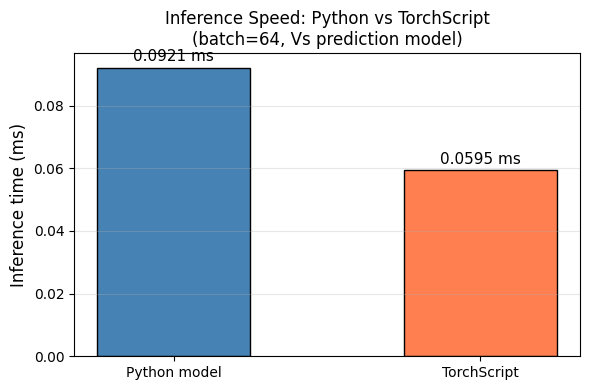

In [8]:
# ───────────────────────────────────────────────────────
# INFERENCE SPEED COMPARISON
# ───────────────────────────────────────────────────────

N_WARMUP   = 10
N_RUNS     = 500
# Use a larger batch to see differences more clearly
bench_input = torch.randn(64, 5)

# --- Warm up ---
for _ in range(N_WARMUP):
    with torch.no_grad():
        _ = model(bench_input)
        _ = loaded_ts(bench_input)

# --- Python model ---
start = time.perf_counter()
for _ in range(N_RUNS):
    with torch.no_grad():
        _ = model(bench_input)
t_python = (time.perf_counter() - start) / N_RUNS * 1000  # ms

# --- TorchScript model ---
start = time.perf_counter()
for _ in range(N_RUNS):
    with torch.no_grad():
        _ = loaded_ts(bench_input)
t_ts = (time.perf_counter() - start) / N_RUNS * 1000  # ms

speedup = t_python / t_ts if t_ts > 0 else float('nan')

print(f"Batch size = 64, averaged over {N_RUNS} runs")
print(f"  Python model   : {t_python:.4f} ms/inference")
print(f"  TorchScript    : {t_ts:.4f} ms/inference")
print(f"  Speed-up       : {speedup:.2f}x")

# Bar chart
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(['Python model', 'TorchScript'], [t_python, t_ts],
               color=['steelblue', 'coral'], edgecolor='k', width=0.5)
for bar, val in zip(bars, [t_python, t_ts]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.001,
            f'{val:.4f} ms', ha='center', va='bottom', fontsize=11)
ax.set_ylabel('Inference time (ms)', fontsize=12)
ax.set_title('Inference Speed: Python vs TorchScript\n(batch=64, Vs prediction model)', fontsize=12)
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

---

## Part 8: Flask API Endpoint (code only — do not run)

In [9]:
# ───────────────────────────────────────────────────────
# FLASK REST API — code demonstration (do not execute)
# ───────────────────────────────────────────────────────
# To run:
#   pip install flask
#   python vs_api.py
# Then POST to http://localhost:5000/predict

FLASK_APP_CODE = '''
from flask import Flask, request, jsonify
import torch
import json
import numpy as np

app = Flask(__name__)

# Load model and config once at startup
with open("config.json") as f:
    CFG = json.load(f)

NET = VsNet(in_features=CFG["architecture"]["in_features"],
            hidden=CFG["architecture"]["hidden_size"])
NET.load_state_dict(torch.load(CFG["weights_file"]))
NET.eval()

MEAN_X  = np.array(CFG["scaler_X"]["mean"])
SCALE_X = np.array(CFG["scaler_X"]["scale"])
MEAN_Y  = CFG["scaler_y"]["mean"]
SCALE_Y = CFG["scaler_y"]["scale"]

@app.route("/predict", methods=["POST"])
def predict():
    data = request.get_json()
    try:
        x = np.array([
            data["depth_m"],
            data["spt_n_value"],
            data["fines_content_pct"],
            data["unit_weight_kNm3"],
            data["effective_stress_kPa"],
        ], dtype=np.float32).reshape(1, -1)

        x_sc = (x - MEAN_X) / SCALE_X
        with torch.no_grad():
            y_sc = NET(torch.tensor(x_sc)).item()
        Vs = y_sc * SCALE_Y + MEAN_Y

        return jsonify({"Vs_ms": round(Vs, 1), "status": "ok",
                        "model_version": CFG["version"]})

    except KeyError as e:
        return jsonify({"status": "error", "message": f"Missing field: {e}"}), 400

@app.route("/health")
def health():
    return jsonify({"status": "healthy", "model": CFG["model_name"],
                    "version": CFG["version"]})

if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5000, debug=False)
'''

print("Flask API code:")
print(FLASK_APP_CODE)

print("\nExample curl request:")
print('''curl -X POST http://localhost:5000/predict \\
     -H "Content-Type: application/json" \\
     -d '{"depth_m": 5.0, "spt_n_value": 15, "fines_content_pct": 30,
          "unit_weight_kNm3": 18.5, "effective_stress_kPa": 45.0}\'''')

Flask API code:

from flask import Flask, request, jsonify
import torch
import json
import numpy as np

app = Flask(__name__)

# Load model and config once at startup
with open("config.json") as f:
    CFG = json.load(f)

NET = VsNet(in_features=CFG["architecture"]["in_features"],
            hidden=CFG["architecture"]["hidden_size"])
NET.load_state_dict(torch.load(CFG["weights_file"]))
NET.eval()

MEAN_X  = np.array(CFG["scaler_X"]["mean"])
SCALE_X = np.array(CFG["scaler_X"]["scale"])
MEAN_Y  = CFG["scaler_y"]["mean"]
SCALE_Y = CFG["scaler_y"]["scale"]

@app.route("/predict", methods=["POST"])
def predict():
    data = request.get_json()
    try:
        x = np.array([
            data["depth_m"],
            data["spt_n_value"],
            data["fines_content_pct"],
            data["unit_weight_kNm3"],
            data["effective_stress_kPa"],
        ], dtype=np.float32).reshape(1, -1)

        x_sc = (x - MEAN_X) / SCALE_X
        with torch.no_grad():
            y_sc = NET(torc

---

## Practice Exercises

### Exercise 1: torch.jit.script
Try `torch.jit.script(model)` instead of `trace`. When does script fail vs trace?

### Exercise 2: Batch predict()
Modify `predict_vs()` to accept a list of soil_params dicts and return a list of results efficiently.

### Exercise 3: Model Registry
Add a `checksum` field to config.json (md5 of the weights file). Verify the checksum in predict_vs() before loading.

In [10]:
# EXERCISE SPACE

# Exercise 1: torch.jit.script
# scripted = torch.jit.script(model)  # may require type annotations

# Exercise 2: Batch predict
# def predict_vs_batch(param_list, model_path, config_path):
#     results = [predict_vs(p, model_path, config_path) for p in param_list]
#     return results

# Exercise 3: checksum
# import hashlib
# def file_md5(path):
#     return hashlib.md5(open(path, 'rb').read()).hexdigest()
# config['checksum_md5'] = file_md5(WEIGHTS_PATH)

---

## Key Takeaways

1. **state_dict is the minimal save format.** It stores only weights and biases — you must have the model class definition available to load it.

2. **TorchScript eliminates the Python dependency.** A traced/scripted model runs anywhere the PyTorch C++ runtime is installed, with no Python interpreter needed.

3. **ONNX enables cross-framework deployment.** ONNX models run in MATLAB, C++, Java, and even embedded systems — critical for geotechnical software integration.

4. **config.json is essential for reproducibility.** Embedding scaler parameters and training metadata means any engineer can reproduce the exact prediction pipeline.

5. **A self-contained predict() protects users from common errors.** Input validation and out-of-range warnings prevent silent extrapolation errors on unusual soil profiles.

---

## How This Connects to ML

| Deployment Concept | Purpose | Geotechnical Relevance |
|---|---|---|
| state_dict | Save/restore weights | Archive trained Vs model |
| TorchScript | Portable compiled model | Field laptop with no Python |
| ONNX | Cross-runtime exchange | Integrate with CAD/geotec software |
| config.json | Version + scaler metadata | Audit trail for regulatory reports |
| predict() wrapper | End-to-end interface | Engineer inputs raw SPT, gets Vs |
| Flask API | HTTP serving | Web-based site classification tool |

**Tomorrow:** Use a 1D CNN to classify raw seismic waveforms as earthquake, blast, or noise.

---

*Day 083 of 100 — Ship it safely, use it confidently!*